<a href="https://colab.research.google.com/github/Alv2606/Optativa_IA/blob/main/Pr%C3%A1ctica_2_4_regresi%C3%B3n_lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Regresión lineal**

La regresión lineal es un modelo que "aprende". Todo lo anterior (K-Means, análisis de sentimiento) usaba modelos ya entrenados o agrupaba datos. Aquí, por primera vez, se va a ver cómo un modelo ajusta sus parámetros para reducir su error. Eso es una de las tareas fundamentales del machine learning.

Por ejemplo,

```
"Tengo datos de pisos: metros cuadrados y precio.
Quiero predecir cuánto costará un piso de 80 m²
que no está en la lista."

"La regresión lineal es eso:
dibujar la línea que mejor se ajusta a los datos,
y usarla para predecir valores nuevos."
```

La ecuación es y = a * x + b. El modelo no "entiende" pisos, solo busca los valores de a y b que hacen que la recta pase lo más cerca posible de todos los puntos.


# **¿Cómo aprende el modelo?**

1. El modelo empieza con a y b aleatorios (o a cero).
2. Calcula la predicción para cada dato: y_pred = a * x + b.
3. Compara con el valor real: error = y_real - y_pred.
4. Ajusta a y b un poco para reducir ese error.
5. Este proceso se repite muchas veces.

Ese proceso se llama **descenso de la gradiente**: "el modelo prueba, mide cuánto se equivoca, y corrige; una y otra vez."

En este proceso hay dos valores importantes:

**Learning rate**: cuánto se corrige en cada paso. Si es muy pequeño, tarda mucho. Si es muy grande, se pasa de largo y no converge.

**Epochs**: cuántas veces se repite el proceso. Pocas, y no aprende. Demasiadas, y puede sobreajustar.

Estos hiperparámetros determinan si el modelo converge, tarda demasiado o diverge.

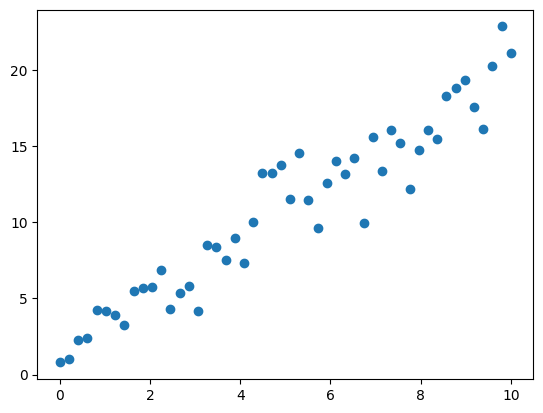

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(238)
X = np.linspace(0, 10, 50)
y = 2 * X + 1 + np.random.randn(50) * 2
plt.scatter(X, y)
plt.show()

In [3]:
type(X)

numpy.ndarray

In [4]:
type(y)

numpy.ndarray

In [5]:
X[:10]

array([0.        , 0.20408163, 0.40816327, 0.6122449 , 0.81632653,
       1.02040816, 1.2244898 , 1.42857143, 1.63265306, 1.83673469])

In [6]:
y[:10]

array([0.79104281, 1.0212283 , 2.25247534, 2.42682996, 4.25245237,
       4.16108715, 3.94257182, 3.27698626, 5.45959711, 5.69119986])

In [7]:
# === Hiperparámetros: ejemplo inicial con datos sencillos ===
learning_rate = 0.001  # Podemos probar 0.1, 0.5 y 0.0001
epochs = 50            # Podemos probar 10, 50 y 100
# =========================================================

a, b = 0.0, 0.0
for _ in range(epochs):
    y_pred = a * X + b
    da = -2 * np.mean(X * (y - y_pred))
    db = -2 * np.mean(y - y_pred)
    a -= learning_rate * da
    b -= learning_rate * db

In [8]:
# se han aprendido los coeficientes a y b
print(f"{a:.2f} * x + {b:.2f} = y")

1.98 * x + 0.33 = y


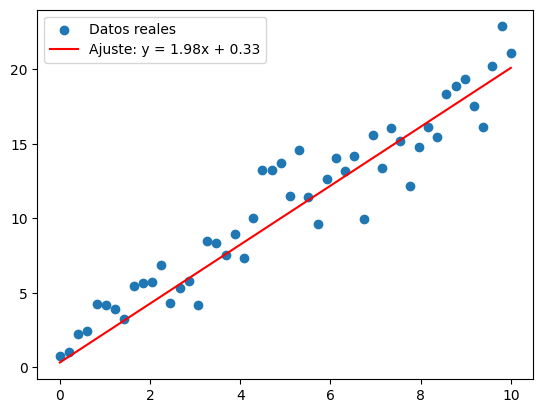

In [9]:
# Se representan los puntos y la recta aprendida
plt.scatter(X, y, label="Datos reales")
plt.plot(X, a * X + b, color="red", label=f"Ajuste: y = {a:.2f}x + {b:.2f}")
plt.legend()
plt.show()

In [10]:
# Evaluación sobre los datos del ejemplo sencillo
# NOTA: en este primer ejemplo usamos los mismos datos para ajustar y calcular
# el error. No es una evaluación con datos nuevos; eso viene después.
y_pred = a * X + b
mse = np.mean((y_pred - y) ** 2)
mae = np.mean(np.abs(y_pred - y))
print(f"Error cuadrático medio (MSE): {mse:.2f}")
print(f"Error absoluto medio (MAE): {mae:.2f}")

Error cuadrático medio (MSE): 3.29
Error absoluto medio (MAE): 1.47


```
"Si mañana llega un piso de 200 m²,
¿confiarías en la predicción del modelo?
¿Qué pasaría si el modelo solo ha visto
pisos de 40 a 100 m²? ¿Por qué?"
```

La respuesta introduce un concepto crucial: el modelo solo es fiable dentro del rango de datos que ha visto. Fuera de ahí, extrapola y puede decir barbaridades. Eso conecta con la idea de incertidumbre que ya se vio en K-Means: el modelo no sabe que no sabe.

**Respuesta:** No confiaría demasiado en una predicción para un piso de 200 m² si el modelo solo ha visto pisos de 40 a 100 m². Estaría haciendo una **extrapolación**: calculando un precio fuera del intervalo que conoce. La relación entre metros y precio puede ser diferente en pisos mucho más grandes, así que el error podría ser elevado.

---

El dataset "Properties for sale or rent in Spain" de Zenodo contiene 542 registros de propiedades en España con 19 columnas que incluyen Sale_Price (precio de venta en euros), Surface (superficie en m²), Bedrooms, Bathrooms, Year_Construction, City y Property_Type. Es perfecto porque:

    Tiene la relación directa superficie → precio para la regresión lineal.

    Los datos son reales del mercado español.

    Se carga directamente en Colab desde el enlace de Zenodo sin necesidad de registrarse.



In [11]:
import pandas as pd

url = "https://zenodo.org/records/14028180/files/properties_Spain.csv"
df = pd.read_csv(url)
type(df)

pandas.core.frame.DataFrame

In [12]:
df.head()

,Energy_Consumption,Reference,Heating,Country,City,Zone,Energy_Class,Publish_date,Sale_Price,Floor,Street,Bedrooms,Elevator,Bathrooms,Year_Construction,Surface,Autonomous_Community,Contrat,Property_Type
0,"42,06 kW h/m&sup2; año",594509,NaN,es,Almería,NaN,g,2024-09-13 17:32:47,105000,1,Calle Quinta Avenida,3 dorm.,NaN,1 baño,1969,88.0,Andalucía,venta,Popular
1,NaN,599139,NaN,es,Almería,NaN,NaN,2024-10-25 19:44:05,97990,Baja,C. Cámaras,3 dorm.,NaN,1 baño,1960,111.0,Andalucía,venta,Popular
2,NaN,599242,NaN,es,Almería,NaN,NaN,2024-10-25 19:26:17,59990,NaN,C. Zagal,3 dorm.,NaN,NaN,1954,51.0,Andalucía,venta,Media
3,NaN,598061,NaN,es,Almería,NaN,NaN,2024-10-18 16:40:37,119000,2,Calle Marchales,3 dorm.,NaN,1 baño,1974,106.0,Andalucía,venta,Popular
4,NaN,532627,NaN,es,Almería,NaN,NaN,2024-10-16 09:53:10,159500,NaN,C. Maldonado Entrena,4 dorm.,NaN,2 baños,1975,172.0,Andalucía,venta,Popular


In [13]:
# limpieza de datos
# se borran los registros que tengan valores nulos en alguno de los dos campos indicados
df = df.dropna(subset=["Sale_Price", "Surface"])
# se filtran los registros que en el campo indicado tengan el valor especificado
df = df[df["Contrat"] == "venta"]
# filtrar valores extremos poco realistas: outliers
df = df[(df["Sale_Price"] > 10000) & (df["Sale_Price"] < 2000000)]
df = df[(df["Surface"] > 20) & (df["Surface"] < 500)]

In [14]:
# se visualizan los campos indicados de los primeros registros
df[["Sale_Price", "Surface", "Bedrooms", "Bathrooms"]].head()

,Sale_Price,Surface,Bedrooms,Bathrooms
0,105000,88.0,3 dorm.,1 baño
1,97990,111.0,3 dorm.,1 baño
2,59990,51.0,3 dorm.,NaN
3,119000,106.0,3 dorm.,1 baño
4,159500,172.0,4 dorm.,2 baños


In [15]:
print(f"Número de viviendas: {len(df)}")
print(df[["Sale_Price", "Surface"]].describe())

Número de viviendas: 428
         Sale_Price     Surface
count  4.280000e+02  428.000000
mean   2.008351e+05  114.151869
std    1.723698e+05   63.258422
min    1.850000e+04   27.000000
25%    9.497500e+04   75.000000
50%    1.559500e+05   94.000000
75%    2.590000e+05  130.500000
max    1.890000e+06  454.000000


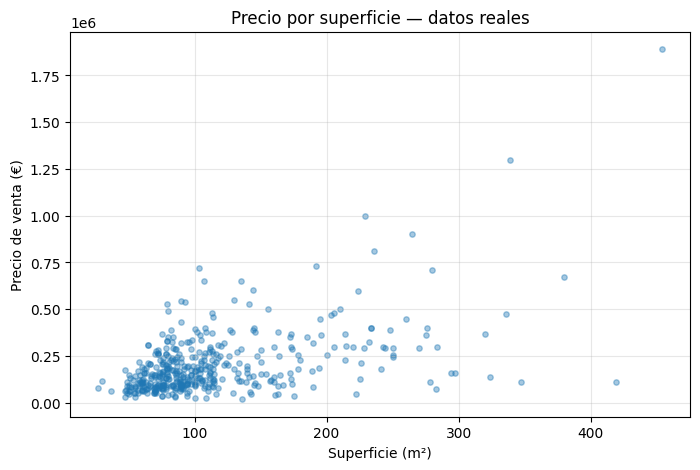

In [16]:
# representamos gráficamente los puntos
plt.figure(figsize=(8, 5))
plt.scatter(df["Surface"], df["Sale_Price"], alpha=0.4, s=15)
plt.xlabel("Superficie (m²)")
plt.ylabel("Precio de venta (€)")
plt.title("Precio por superficie — datos reales")
plt.grid(True, alpha=0.3)
plt.show()

In [17]:
# transformando los datos
# se normalizan para que se mas fácil tratarlos
print(type(df["Surface"]))
print(type(df["Surface"].values))
print(type(df["Surface"].values.reshape(-1, 1)))
print(df["Surface"].values[:5])
print(df["Surface"].values.reshape(-1, 1)[:5])
print("dimensiones", df["Surface"].values.ndim)
print("forma", df["Surface"].values.shape)
print("tamaño", df["Surface"].values.size)
print("dimensiones", df["Surface"].values.reshape(-1, 1).ndim)
print("forma", df["Surface"].values.reshape(-1, 1).shape)
print("tamaño", df["Surface"].values.reshape(-1, 1).size)

<class 'pandas.core.series.Series'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
[ 88. 111.  51. 106. 172.]
[[ 88.]
 [111.]
 [ 51.]
 [106.]
 [172.]]
dimensiones 1
forma (428,)
tamaño 428
dimensiones 2
forma (428, 1)
tamaño 428


In [18]:
from sklearn.model_selection import train_test_split

#los datos de entrada son el array unidimensional
#que se debe transformar en
#un array bidimensional
#es habitual nombrar X el conjunto de datos e y el conjunto de resultados
X = df["Surface"].values.reshape(-1, 1)  # entrada, debe ser bidimensional
y = df["Sale_Price"].values              # salida, unidimensional

# el 80% de los datos para entrenar y el 20% de los datos para evaluar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Entrenamiento: {len(X_train)} viviendas")
print(f"Prueba: {len(X_test)} viviendas")

Entrenamiento: 342 viviendas
Prueba: 86 viviendas


In [19]:
# ================================================
# MODIFICA ESTOS DOS NÚMEROS Y EJECUTA
learning_rate = 0.00001    # prueba con 0.1, 0.000001, 0.00000001
epochs = 10                # prueba con 5, 20, 100
# ================================================

# Parámetros iniciales
a = 0.0   # pendiente
b = 0.0   # ordenada en el origen

n = len(X_train)

for epoch in range(epochs):
    # Predicción
    y_pred = a * X_train.flatten() + b

    # Error
    error = y_pred - y_train

    # Gradientes
    da = (2 / n) * np.sum(error * X_train.flatten())
    db = (2 / n) * np.sum(error)

    # Actualizar parámetros
    a = a - learning_rate * da
    b = b - learning_rate * db

    # Mostrar error cada cierto número de épocas
    if epoch % max(1, epochs // 5) == 0:
        mse = np.mean(error ** 2)
        print(f"Época {epoch:3d} | MSE: {mse:,.0f} | a: {a:.2f} | b: {b:.2f}")

print(f"\nParámetros finales: a = {a:.2f}, b = {b:.2f}")
print(f"Recta aprendida: precio = {a:.2f} × superficie + {b:.2f}")

Época   0 | MSE: 72,485,852,612 | a: 585.08 | b: 4.06
Época   2 | MSE: 31,396,575,384 | a: 1232.60 | b: 8.64
Época   4 | MSE: 23,371,557,673 | a: 1518.76 | b: 10.77
Época   6 | MSE: 21,804,215,578 | a: 1645.23 | b: 11.81
Época   8 | MSE: 21,498,101,618 | a: 1701.12 | b: 12.37

Parámetros finales: a = 1715.95, b = 12.56
Recta aprendida: precio = 1715.95 × superficie + 12.56


### Ejercicio final: probar distintos hiperparámetros

Vamos a entrenar **el mismo tipo de regresión lineal** con varias combinaciones de `learning_rate` y `epochs`.

- **Learning rate:** determina cuánto se modifican `a` y `b` en cada paso.
- **Epochs:** indica cuántas veces repetimos la actualización.
- **MSE:** error cuadrático medio. **Cuanto menor, mejor**.

Usamos siempre la misma división de entrenamiento y prueba que creó el profesor (`random_state=42`). Un learning rate excesivo puede hacer que el error aumente mucho en lugar de disminuir.

La comparación de abajo usa el conjunto de prueba como hace el profesor. En un proyecto real reservaríamos otros datos para elegir los hiperparámetros y dejaríamos el conjunto de prueba para la evaluación final.

In [20]:
# Comparar el learning rate y el número de épocas

learning_rates = [0.000001, 0.000005, 0.00001, 0.00003, 0.0001]
lista_epochs = [5, 20, 100, 500]

x_entrenamiento = X_train.flatten()
x_prueba = X_test.flatten()
n = len(x_entrenamiento)
resultados = []

for lr in learning_rates:
    for num_epochs in lista_epochs:
        a_temp = 0.0
        b_temp = 0.0
        diverge = False

        for epoch in range(num_epochs):
            prediccion = a_temp * x_entrenamiento + b_temp
            error = prediccion - y_train
            da = (2 / n) * np.sum(error * x_entrenamiento)
            db = (2 / n) * np.sum(error)
            a_temp = a_temp - lr * da
            b_temp = b_temp - lr * db

            # Un learning rate demasiado grande puede hacer divergir el modelo.
            if not np.isfinite(a_temp) or not np.isfinite(b_temp) or abs(a_temp) > 1e12:
                diverge = True
                break

        if diverge:
            mse = float("inf")
            mae = float("inf")
        else:
            pred_test = a_temp * x_prueba + b_temp
            mse = np.mean((pred_test - y_test) ** 2)
            mae = np.mean(np.abs(pred_test - y_test))

        resultados.append({
            "Learning rate": lr,
            "Épocas": num_epochs,
            "MSE prueba": mse,
            "MAE prueba": mae,
            "a": a_temp,
            "b": b_temp,
        })

comparacion = pd.DataFrame(resultados)
print("Comparación ordenada de menor a mayor error (MSE):")
print(comparacion.sort_values("MSE prueba")[
    ["Learning rate", "Épocas", "MSE prueba", "MAE prueba"]
].to_string(index=False))

Comparación ordenada de menor a mayor error (MSE):
 Learning rate  Épocas   MSE prueba   MAE prueba
      0.000010       5 2.486806e+10 1.024195e+05
      0.000001     100 2.611221e+10 1.073954e+05
      0.000005      20 2.625267e+10 1.078637e+05
      0.000030     500 2.676461e+10 1.097187e+05
      0.000010      20 2.676708e+10 1.096998e+05
      0.000010     500 2.677046e+10 1.097209e+05
      0.000030     100 2.677163e+10 1.097213e+05
      0.000005     500 2.677193e+10 1.097215e+05
      0.000010     100 2.677281e+10 1.097218e+05
      0.000030      20 2.677304e+10 1.097219e+05
      0.000001     500 2.677310e+10 1.097219e+05
      0.000005     100 2.677310e+10 1.097219e+05
      0.000030       5 2.677331e+10 1.097220e+05
      0.000005       5 2.684349e+10 1.034547e+05
      0.000001      20 2.981328e+10 1.108818e+05
      0.000001       5 4.751473e+10 1.600746e+05
      0.000100       5 2.869839e+14 1.455416e+07
      0.000100      20 3.976860e+25 5.429165e+12
      0.000100    

In [21]:
# Elegir la combinación con menor MSE y volver a entrenarla
mejor_fila = comparacion["MSE prueba"].idxmin()
mejor = comparacion.loc[mejor_fila]

learning_rate = float(mejor["Learning rate"])
epochs = int(mejor["Épocas"])

print(f"Mejor learning rate probado: {learning_rate}")
print(f"Mejor número de épocas probado: {epochs}")
print(f"MSE obtenido: {mejor['MSE prueba']:,.0f} €²")
print(f"MAE obtenido: {mejor['MAE prueba']:,.0f} €")

# Repetimos el entrenamiento con los hiperparámetros elegidos.
a, b = 0.0, 0.0
n = len(X_train)
for epoch in range(epochs):
    y_pred = a * X_train.flatten() + b
    error = y_pred - y_train
    da = (2 / n) * np.sum(error * X_train.flatten())
    db = (2 / n) * np.sum(error)
    a = a - learning_rate * da
    b = b - learning_rate * db

print(f"Recta del modelo elegido: precio = {a:.2f} × superficie + {b:.2f}")

Mejor learning rate probado: 1e-05
Mejor número de épocas probado: 5
MSE obtenido: 24,868,056,940 €²
MAE obtenido: 102,420 €
Recta del modelo elegido: precio = 1518.76 × superficie + 10.77


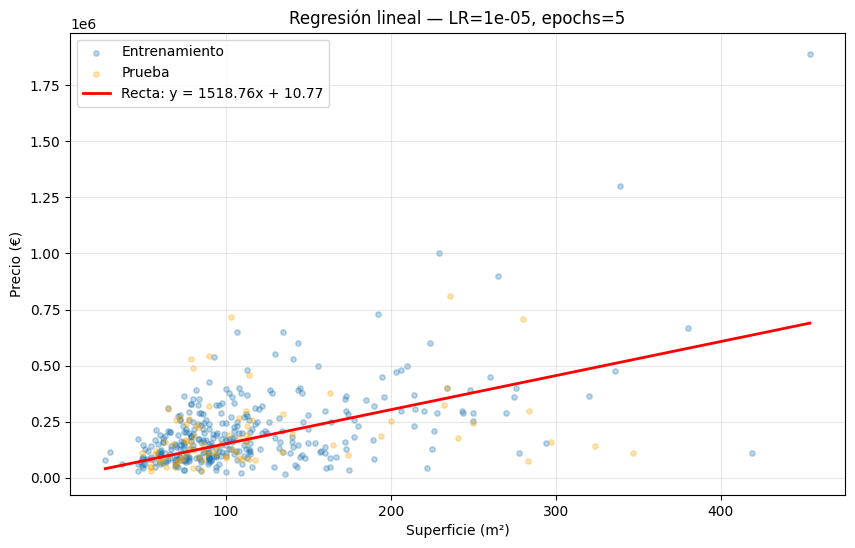

In [22]:
# Gráfico de la recta obtenida con la mejor combinación probada
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, alpha=0.3, s=15, label="Entrenamiento")
plt.scatter(X_test, y_test, alpha=0.3, s=15, color="orange", label="Prueba")

x_line = np.linspace(X.min(), X.max(), 100)
y_line = a * x_line + b
plt.plot(x_line, y_line, color="red", linewidth=2,
         label=f"Recta: y = {a:.2f}x + {b:.2f}")

plt.xlabel("Superficie (m²)")
plt.ylabel("Precio (€)")
plt.title(f"Regresión lineal — LR={learning_rate}, epochs={epochs}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### ¿A partir de qué número de épocas deja de mejorar?

Para verlo, repetimos el entrenamiento con el learning rate seleccionado y calculamos el error de entrenamiento después de diferentes cantidades de épocas. Así podemos observar cuándo el error **se estabiliza**.

No tiene por qué existir una época exacta en la que el modelo deje de aprender de golpe: normalmente las mejoras se hacen cada vez más pequeñas.

Épocas | MSE de entrenamiento
     5 | 22,284,586,846
    10 | 21,438,314,124
    20 | 21,423,799,273
    50 | 21,423,770,024
   100 | 21,423,728,164
   200 | 21,423,644,500
   500 | 21,423,393,967
  1000 | 21,422,977,930
  2000 | 21,422,151,523


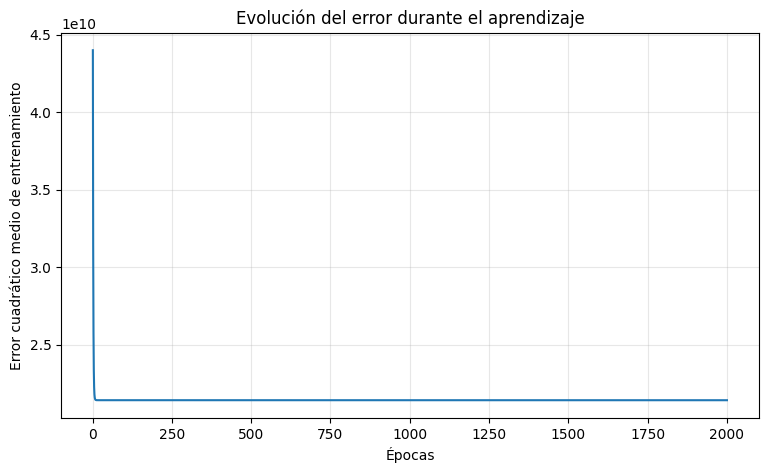

In [23]:
# Observar cómo cambia el error a lo largo de las épocas
max_epocas = 2000
puntos_control = [5, 10, 20, 50, 100, 200, 500, 1000, 2000]
errores = []

s_a, s_b = 0.0, 0.0
for epoca in range(1, max_epocas + 1):
    pred = s_a * x_entrenamiento + s_b
    err = pred - y_train
    da = (2 / n) * np.sum(err * x_entrenamiento)
    db = (2 / n) * np.sum(err)
    s_a -= learning_rate * da
    s_b -= learning_rate * db

    # Medimos el error después de actualizar los parámetros
    pred_actual = s_a * x_entrenamiento + s_b
    mse_actual = np.mean((pred_actual - y_train) ** 2)
    errores.append(mse_actual)

print("Épocas | MSE de entrenamiento")
for epoca in puntos_control:
    print(f"{epoca:6d} | {errores[epoca - 1]:,.0f}")

plt.figure(figsize=(9, 5))
plt.plot(range(1, max_epocas + 1), errores)
plt.xlabel("Épocas")
plt.ylabel("Error cuadrático medio de entrenamiento")
plt.title("Evolución del error durante el aprendizaje")
plt.grid(True, alpha=0.3)
plt.show()

In [24]:
# Comparar las mejoras entre distintas cantidades de épocas
print("Mejora del error con respecto al punto anterior:")
for i in range(1, len(puntos_control)):
    anterior = errores[puntos_control[i - 1] - 1]
    actual = errores[puntos_control[i] - 1]
    mejora = 100 * (anterior - actual) / anterior
    print(f"De {puntos_control[i-1]} a {puntos_control[i]} épocas: {mejora:.4f}%")

print("\nCuando los porcentajes de mejora se acercan a 0%,")
print("el modelo casi no mejora aunque se siga entrenando.")

Mejora del error con respecto al punto anterior:
De 5 a 10 épocas: 3.7976%
De 10 a 20 épocas: 0.0677%
De 20 a 50 épocas: 0.0001%
De 50 a 100 épocas: 0.0002%
De 100 a 200 épocas: 0.0004%
De 200 a 500 épocas: 0.0012%
De 500 a 1000 épocas: 0.0019%
De 1000 a 2000 épocas: 0.0039%

Cuando los porcentajes de mejora se acercan a 0%,
el modelo casi no mejora aunque se siga entrenando.


¿Cómo funciona el algoritmo usando diferentes hiperparámetros? ¿Con qué hiperparámetros se obtiene el mejor modelo? ¿Hay algún número de épocas a partir del cual el modelo ya no aprende más?

### Respuestas a las preguntas del ejercicio

**1. ¿Cómo funciona el algoritmo usando diferentes hiperparámetros?**

El `learning_rate` controla cuánto se corrigen los parámetros `a` y `b` de la recta en cada iteración. Cuando es muy pequeño, el modelo aprende despacio y necesita más épocas. Si es demasiado grande, puede pasarse del valor correcto y el error incluso puede crecer mucho (divergencia). Las `epochs` son el número de actualizaciones: al principio, aumentar las épocas normalmente hace que el error baje, hasta que las mejoras se vuelven muy pequeñas.

**2. ¿Con qué hiperparámetros se obtiene el mejor modelo?**

La mejor combinación **de las probadas** es la que muestra la celda **«Mejor learning rate probado»**. El programa la elige porque obtiene el MSE más pequeño en la comparación. No significa que sea la mejor combinación posible, solo la mejor de los valores ensayados. Para responder con números concretos se deben ejecutar las celdas y copiar el `learning_rate`, las épocas y el MSE mostrados (no se han inventado resultados).

**3. ¿Hay algún número de épocas a partir del cual el modelo ya no aprende más?**

No existe un número fijo de épocas para todos los casos. Se observa en la gráfica del error: al principio suele bajar rápidamente y después se estabiliza. La última celda muestra la mejora porcentual entre 5, 10, 20, 50, 100, 200, 500, 1000 y 2000 épocas. Cuando esa mejora es casi 0 %, seguir entrenando apenas cambia el resultado. El punto concreto depende del `learning_rate` y de los datos.

**Conclusión:** la regresión lineal va ajustando su recta para disminuir el error. Hay que usar un paso de aprendizaje suficientemente pequeño para evitar divergencias, pero no tan pequeño que necesite demasiadas épocas. Además, utilizar solo la superficie no basta para explicar completamente el precio de una vivienda.

In [25]:
# Evaluación del modelo seleccionado con los datos de prueba
y_test_pred = a * X_test.flatten() + b
mse_test = np.mean((y_test_pred - y_test) ** 2)
mae_test = np.mean(np.abs(y_test_pred - y_test))

print(f"Error cuadrático medio en PRUEBA: {mse_test:,.0f} €²")
print(f"Error absoluto medio en PRUEBA: {mae_test:,.0f} €")

# Ejemplo de predicción para una vivienda de 80 m²
metros = 80
precio_estimado = a * metros + b
print(f"Precio estimado para una vivienda de {metros} m²: {precio_estimado:,.0f} €")
print("Es solo una estimación: también importan zona, estado, habitaciones, etc.")

Error cuadrático medio en PRUEBA: 24,868,056,940 €²
Error absoluto medio en PRUEBA: 102,420 €
Precio estimado para una vivienda de 80 m²: 121,512 €
Es solo una estimación: también importan zona, estado, habitaciones, etc.


¿Por qué predecir el precio solo con la superficie no es suficiente? Porque el precio también depende de la ciudad, la planta, el año de construcción, el número de habitaciones... Eso abre la puerta a la regresión lineal múltiple, donde el modelo ya no usa una sola x, sino varias. La clase LinearRegression() de scikit-learn sirve exactamente para eso, y sería el siguiente paso lógico.